# Hedging an insurance portfolio

This experiment compares three strategies on the same market and mortality scenarios:

- **No hedge:** invest the initial premium in the bank account.
- **Static hedge:** use the initial fund deltas, adjusting positions for the surviving notionals of each contract type.
- **Dynamic hedge:** recompute the deltas at each rebalancing date using the current fund, carbon intensities and surviving population.

All costs are discounted to time zero. Positive costs mean additional funding is required.

Python configures and analyses the experiment; the simulation runs in C++.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from carbonfund_experiments import (
    Table,
    validate_config,
    run_experiment,
    load_result,
)

### Execution and output

Choose the project directory, compiled executable and output directory.

- `OVERWRITE_EXISTING`: allow replacing an existing experiment.
- `SAVE_PLOTS`: save figures alongside the numerical results.
- `SHOW_PROGRESS`: display progress during execution.
- `SCIENTIFIC_DIGITS` and `FIXED_DIGITS`: control table formatting only.

Use a different `RUN_NAME` when changing simulation inputs to preserve previous experiments.

In [2]:
PROJECT = Path(
    "/home/edoardolombardo/Documents/codes/CarbonFund_UL"
)

EXECUTABLE = (
    PROJECT / "build-paper-release" / "carbonfund_experiment"
)

RUN_NAME = "hedging_EI_CIR_T20_01"

OUTPUT_DIRECTORY = (
    PROJECT / "results" / "notebooks" / RUN_NAME
)

OVERWRITE_EXISTING = True  # True to overwrite existing results, False to avoid overwriting existing results
SAVE_PLOTS = True
SHOW_PROGRESS = True

SCIENTIFIC_DIGITS = 4
FIXED_DIGITS = 4

assert EXECUTABLE.is_file(), (
    f"Executable not found: {EXECUTABLE}"
)

### Financial market

The market contains four stocks.

- `risk_free_rate`: continuously compounded annual bank-account rate.
- `expected_returns`: annual stock drifts under the physical measure.
- `volatilities`: annual stock volatilities.
- `correlations`: correlation matrix of the stock returns.

The covariance matrix is constructed from volatilities and correlations. The correlation matrix must be symmetric, positive definite and have unit diagonal.

Outer hedging scenarios use the physical dynamics. Valuations use the minimal martingale measure.

In [3]:
market = {
    "risk_free_rate": 0.05,

    "expected_returns": [
        0.25, 0.15, 0.10, 0.08
    ],

    "volatilities": [
        0.30, 0.25, 0.20, 0.16
    ],

    "correlations": [
        [1.00, 0.44, 0.39, 0.32],
        [0.44, 1.00, 0.30, 0.33],
        [0.39, 0.30, 1.00, 0.31],
        [0.32, 0.33, 0.31, 1.00],
    ],
}

### Carbon intensities

Choose `CARBON_MODEL` from `"OU"`, `"GeoOU"` and `"CIR"`. Each model has four carbon intensities, in the same order as the stocks.

- **OU:** mean-reverting carbon levels; negative values are possible.
- **GeoOU:** mean-reverting log carbon levels; carbon intensities remain positive.
- **CIR:** square-root diffusion with nonnegative carbon levels.

`initial` is always supplied in carbon levels. GeoOU uses `long_run_log_mean`; OU and CIR use `long_run_mean`.

The CIR inputs below use the previous pricing calibration. The OU and GeoOU inputs are illustrative alternatives: their volatility parameters have different units.

For the implemented CIR scheme, each component must satisfy
$\kappa_i\theta_i \geq \sigma_i^2/4$.

In [4]:
CARBON_MODEL = "CIR"

carbon_parameters = {
    "OU": {
        "initial": [
            5000.0, 4000.0, 3000.0, 1000.0
        ],
        "long_run_mean": [
            2500.0, 2000.0, 1500.0, 500.0
        ],
        "mean_reversion": [
            0.05, 0.05, 0.05, 0.05
        ],
        "volatility": [
            300.0, 300.0, 300.0, 300.0
        ],
    },

    "GeoOU": {
        "initial": [
            5000.0, 4000.0, 3000.0, 1000.0
        ],
        "long_run_log_mean": [
            math.log(2500.0),
            math.log(2000.0),
            math.log(1500.0),
            math.log(500.0),
        ],
        "mean_reversion": [
            0.05, 0.05, 0.05, 0.05
        ],
        "volatility": [
            0.10, 0.10, 0.10, 0.10
        ],
    },

    "CIR": {
        "initial": [
            5000.0, 4000.0, 3000.0, 1000.0
        ],
        "long_run_mean": [
            2500.0, 2000.0, 1500.0, 500.0
        ],
        "mean_reversion": [
            0.05, 0.05, 0.05, 0.05
        ],
        "volatility": [
            3.0, 3.0, 3.0, 3.0
        ],
    },
}

carbon = {
    "model": CARBON_MODEL,
    **carbon_parameters[CARBON_MODEL],
}

### Fund preferences

- `risk_aversion` ($\gamma>0$): weight of financial risk in the allocation rule.
- `carbon_penalty` ($\alpha\geq0$): weight of the carbon penalty.

Setting `carbon_penalty` to zero removes carbon preferences.

The fund allocation changes as the carbon intensities evolve.

In [5]:
fund = {
    "risk_aversion": 1.0,
    "carbon_penalty": 0.0025,
}

### Contract terms

All policies in this experiment share these benefit terms.

The guaranteed fund benefit at time $t$ is

$$
G_t = \min\{\max(X_t,L(t)),U(t)\},
$$

where $L(t)=L_0e^{g_Lt}$ and $U(t)=U_0e^{g_Ut}$.

- `fund_value`: initial fund value $X_0$.
- `maturity`: contract horizon, in years.
- `minimum_guarantee`, `maximum_guarantee`: initial guarantee levels.
- The two growth rates determine the future guarantee levels.
- `endowment_death_benefit_fraction`: multiplier applied to the EI death benefit.

PE pays on survival to maturity; TI pays on death before maturity; EI combines both benefits.

Each policy's notional multiplies its benefit.

In [6]:
contract = {
    "fund_value": 1.0,
    "maturity": 20.0,

    "minimum_guarantee": 1.0,
    "maximum_guarantee": 1.0,

    "minimum_guarantee_growth_rate": 0.05,
    "maximum_guarantee_growth_rate": 0.50,

    "endowment_death_benefit_fraction": 1.0,
}

### Mortality

For a policyholder initially aged $a$, the Gompertz–Makeham mortality intensity is

$$
\lambda_a(t)
=
\xi+\frac{1}{b}
\exp\left(\frac{a+t-m}{b}\right).
$$

- `xi`: age-independent Makeham component.
- `m`: Gompertz location parameter.
- `b`: positive Gompertz scale parameter.

Deaths are simulated individually in the outer hedging scenarios. Inner valuations integrate mortality analytically.

In [7]:
mortality = {
    "xi": 0.0041959,
    "m": 79.6921211,
    "b": 11.5818911,
}

### Insured population

Each group specifies a contract type, number of people, initial age and individual notional.

The groups are expanded into individual policyholders so that deaths can be simulated separately.

The starting portfolio contains 100 EI policies. Change the counts to include PE or TI policies, or add groups with different ages and notionals.

A single policy with notional 100,000 is different from 100 policies with notional 1,000: their mortality risk differs.

In [69]:
population_groups = [
    {
        "type": "PE",
        "count": 1000,
        "age": 60.0,
        "notional": 1.0,
    },
    {
        "type": "TI",
        "count": 0,
        "age": 60.0,
        "notional": 1.0,
    },
    {
        "type": "EI",
        "count": 0,
        "age": 60.0,
        "notional": 0.001,
    },
]

if any(
    type(group["count"]) is not int or group["count"] < 0
    for group in population_groups
):
    raise ValueError("Population counts must be nonnegative integers.")

population = [
    {
        "type": group["type"],
        "age": group["age"],
        "notional": group["notional"],
    }
    for group in population_groups
    for _ in range(group["count"])
]

print("Policyholders:", len(population))
print(
    "Total notional:",
    sum(person["notional"] for person in population),
)

Policyholders: 1000
Total notional: 1000.0


### Outer hedging scenarios

These settings determine the simulated experience of the insurer.

- `outer_scenarios`: number of independent scenarios.
- `intervals`: number of intervals in the market and hedging grid.
- `progress_every`: print progress after this many scenarios; zero disables it.
- The three seeds control carbon, financial and mortality randomness.

Each scenario supplies the same fund path, carbon path and deaths to all three strategies.

With maturity 20 and 20 intervals, hedging is annual. Death benefits are settled at the right endpoint of the interval containing the death.

In [70]:
outer_simulation = {
    "outer_scenarios": 1000,
    "intervals": 1040,
    "progress_every": 200,
    "threads": 16,

    "carbon_seed": 2026101801,
    "financial_seed": 2026101802,
    "mortality_seed": 2026101803,
}

### Initial premium and deltas

The initial portfolio premium and deltas are computed once using these valuation settings.

- `paths`: Monte Carlo path budget.
- `intervals`: valuation time grid over the full contract horizon.
- `configuration`: selected estimator.
- The two seeds control the valuation streams.

Available estimators are `standard`, `standard_antithetic`, `conditioned` and `conditioned_antithetic`.

All three hedging strategies start with the same computed premium. The static and dynamic strategies also share the computed initial deltas.

In [71]:
initial_valuation = {
    "paths": 1600,
    "intervals": 1040,

    "configuration": "conditioned_antithetic",

    "carbon_seed": 2026101804,
    "financial_seed": 2026101805,
}

### Revaluation during dynamic hedging

These settings control the inner valuations at later rebalancing dates.

Each valuation uses the current fund value, current carbon intensities, attained ages and surviving portfolio. Guarantee levels retain their original contractual growth.

`intervals` specifies the valuation grid over the original horizon. The number of remaining steps decreases as maturity approaches.

Increasing `paths` reduces numerical noise in the estimated deltas. This budget is separate from the number of outer scenarios.

All seven seeds across the outer simulation, initial valuation and revaluation must differ. Financial seeds remain required when using conditioned estimators.

In [72]:
revaluation = {
    "paths": 40,
    "intervals": 256,
    "minimum_intervals": 4,

    "configuration": "conditioned_antithetic",

    "carbon_seed": 2026101806,
    "financial_seed": 2026101807,
}

### Statistical analysis and figures

- `normalization`: report aggregate costs, costs per policy, or costs per unit of notional.
- `confidence_level`: confidence level for mean-cost intervals.
- `comparison_family_size`: Bonferroni family size; three covers all strategy pairs. Zero selects it automatically.
- `quantiles`: requested cost quantiles.
- `expected_shortfall_levels`: average costs in the upper tail.
- `bins`: histogram bin count.
- `zoom`, `plot_range`: optional plotting limits in the chosen normalized units; `None` selects automatic limits.
- `figure_formats`, `dpi`, `title`: figure output settings.

Plotting limits do not restrict the observations used for statistics.

With 1,000 scenarios, the upper 1% contains only about ten observations. Larger samples are needed for stable extreme-tail estimates.

In [73]:
analysis = {
    "normalization": "per_policy",

    "confidence_level": 0.95,
    "comparison_family_size": 3,

    "quantiles": [
        0.025,
        0.50,
        0.90,
        0.95,
        0.975,
        0.99,
    ],

    "expected_shortfall_levels": [
        0.95,
        0.99,
    ],

    "bins": 70,

    "zoom": None,
    "plot_range": None,

    "figure_formats": ["png", "pdf"],
    "dpi": 180,

    "title": (
        "EI portfolio: no hedge, static hedge and dynamic hedge"
    ),
}

### Assemble and validate the configuration

This cell combines all explicitly defined input blocks.

`experiment="hedging"` selects the hedging engine. No separate `pricing` block is needed: initial and later valuations use the settings inside `hedging`.

`validate_config(config)` checks the configuration before launching C++.

The notes are saved with the experiment and do not affect calculations.

In [74]:
config = {
    "schema_version": 1,
    "experiment": "hedging",

    "market": market,
    "carbon": carbon,
    "fund": fund,
    "contract": contract,
    "mortality": mortality,
    "population": population,

    "hedging": {
        **outer_simulation,
        "initial": initial_valuation,
        "revaluation": revaluation,
    },

    "analysis": analysis,

    "notes": (
        "Explicit notebook inputs. "
        "CIR starting configuration uses the paper financial/carbon "
        "calibration and corrected mortality parameter. "
        "Numerical budgets are chosen for this example."
    ),
}

validate_config(config)

print(json.dumps(config, indent=2))

{
  "schema_version": 1,
  "experiment": "hedging",
  "market": {
    "risk_free_rate": 0.05,
    "expected_returns": [
      0.25,
      0.15,
      0.1,
      0.08
    ],
    "volatilities": [
      0.3,
      0.25,
      0.2,
      0.16
    ],
    "correlations": [
      [
        1.0,
        0.44,
        0.39,
        0.32
      ],
      [
        0.44,
        1.0,
        0.3,
        0.33
      ],
      [
        0.39,
        0.3,
        1.0,
        0.31
      ],
      [
        0.32,
        0.33,
        0.31,
        1.0
      ]
    ]
  },
  "carbon": {
    "model": "CIR",
    "initial": [
      5000.0,
      4000.0,
      3000.0,
      1000.0
    ],
    "long_run_mean": [
      2500.0,
      2000.0,
      1500.0,
      500.0
    ],
    "mean_reversion": [
      0.05,
      0.05,
      0.05,
      0.05
    ],
    "volatility": [
      3.0,
      3.0,
      3.0,
      3.0
    ]
  },
  "fund": {
    "risk_aversion": 1.0,
    "carbon_penalty": 0.0025
  },
  "contract": {
  

### Run the experiment

The C++ executable computes the initial valuation, generates the outer scenarios and evaluates all three hedging strategies.

For strategy $s$, the cost is

$$
C^{(s)}
=
\text{discounted claims}
-
\text{initial premium}
-
\text{discounted trading gains}^{(s)}.
$$

Positive values represent additional funding required; negative values represent a surplus.

The output directory contains the configuration, metadata, scenario-level `hedging.csv`, summary statistics, paired comparisons and requested figures.

In [75]:
# Copy the selected thread count into the effective configuration.
config["hedging"]["threads"] = outer_simulation["threads"]

validate_config(config)

print("Requested threads:", config["hedging"]["threads"])
print("Executable:", EXECUTABLE)

result = run_experiment(
    config=config,
    output_dir=OUTPUT_DIRECTORY,
    binary=EXECUTABLE,
    overwrite=OVERWRITE_EXISTING,
    plots=SAVE_PLOTS,
    progress=SHOW_PROGRESS,
)

info = result.metadata["run"]

print("OpenMP enabled:", info["openmp_enabled"])
print("Actual threads:", info["threads_used"])
print("Elapsed seconds:", info["simulation_wall_seconds"])
print("CPU seconds:", info["simulation_cpu_seconds"])

Requested threads: 16
Executable: /home/edoardolombardo/Documents/codes/CarbonFund_UL/build-paper-release/carbonfund_experiment
Hedging scenarios completed: 200/1000
Hedging scenarios completed: 400/1000
Hedging scenarios completed: 600/1000
Hedging scenarios completed: 800/1000
Hedging scenarios completed: 1000/1000
Saved experiment to /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/notebooks/hedging_EI_CIR_T20_01
OpenMP enabled: True
Actual threads: 16
Elapsed seconds: 223.848043048
CPU seconds: 3248.372506


### Table formatting

This helper displays numerical values in scientific notation.

Variance reductions and execution times use fixed notation. Formatting affects only the displayed tables; saved numerical results retain their precision.

In [15]:
def formatted_table(rows):
    formatted = []

    for row in rows:
        output = {}

        for key, value in row.items():
            if isinstance(value, float):
                if not math.isfinite(value):
                    output[key] = ""

                elif key == "variance_reduction_percent":
                    output[key] = (
                        f"{value:.{FIXED_DIGITS}f}%"
                    )

                elif key.endswith("_seconds"):
                    output[key] = (
                        f"{value:.{FIXED_DIGITS}f}"
                    )

                else:
                    output[key] = (
                        f"{value:.{SCIENTIFIC_DIGITS}e}"
                    )
            else:
                output[key] = value

        formatted.append(output)

    return Table(formatted)

### Initial valuation and runtime

Inspect the initial premium, initial deltas, actual valuation path budgets and execution times.

The premium and deltas in this diagnostic table are aggregate portfolio quantities, irrespective of the normalization chosen for cost analysis.

Deltas already include the policy notionals.

In [24]:
run_information = result.metadata["run"]

initial_deltas = run_information[
    "initial_deltas_PE_TI_EI"
]

diagnostics = [
    {
        "initial_price": run_information["initial_price"],

        "initial_delta_PE": initial_deltas[0],
        "initial_delta_TI": initial_deltas[1],
        "initial_delta_EI": initial_deltas[2],

        "initial_actual_paths": run_information[
            "initial_actual_paths"
        ],

        "revaluation_actual_paths": run_information[
            "revaluation_actual_paths"
        ],

        "initial_cpu_seconds": run_information[
            "initial_cpu_seconds"
        ],

        "simulation_cpu_seconds": run_information[
            "simulation_cpu_seconds"
        ],

        "wall_seconds": result.metadata["wall_seconds"],
    }
]

display(formatted_table(diagnostics))

initial_price,initial_delta_PE,initial_delta_TI,initial_delta_EI,initial_actual_paths,revaluation_actual_paths,initial_cpu_seconds,simulation_cpu_seconds,wall_seconds
1.1803e+00,0.0000e+00,0.0000e+00,5.8955e-01,4000,40,4.1068,3343.3104,229.9417


### Hedging-cost statistics

For each strategy, the summary reports:

- Mean cost, sample variance and standard deviation.
- Standard error and confidence interval of the mean.
- Minimum, maximum and probability of requiring additional funding.
- Requested quantiles and upper-tail expected shortfalls.

For $K$ scenarios, the mean standard error is $s/\sqrt{K}$.

The cost variance measures the spread of simulated hedging outcomes. It includes mortality and market risk, together with numerical noise from the inner valuations.

The initial valuation is shared across scenarios; these intervals do not include uncertainty from repeating that initial valuation.

In [76]:
summary = result.summary()

display(formatted_table(summary))

strategy,n,mean,variance,std,mean_se,mean_ci_low,mean_ci_high,min,max,probability_positive,q2.5,q50,q90,q95,q97.5,q99,es95,es99
no_hedge,1000,1.1546e+00,1.1119e+00,1.0545e+00,3.3345e-02,1.0892e+00,1.2201e+00,-1.0902e-01,9.2899e+00,9.7000e-01,-8.6840e-03,9.0006e-01,2.3725e+00,3.0732e+00,3.7365e+00,5.2284e+00,4.3579e+00,6.6969e+00
static_hedge,1000,6.6634e-01,4.6611e-01,6.8273e-01,2.1590e-02,6.2398e-01,7.0871e-01,-1.3058e-01,6.1916e+00,9.3200e-01,-5.9014e-02,5.0790e-01,1.4284e+00,1.8518e+00,2.3432e+00,3.3638e+00,2.7637e+00,4.3680e+00
dynamic_hedge,1000,-5.8666e-04,2.5709e-03,5.0704e-02,1.6034e-03,-3.7331e-03,2.5597e-03,-2.3228e-01,2.3323e-01,5.0000e-01,-1.1799e-01,2.3765e-05,5.6952e-02,7.5455e-02,9.2740e-02,1.2323e-01,1.0683e-01,1.5976e-01


### Paired strategy comparisons

Each comparison uses the scenario-by-scenario difference

$$
D_j=C_j^{\mathrm{candidate}}-C_j^{\mathrm{reference}}.
$$

A negative mean difference means the candidate has a lower average cost.

The variance reduction is

$$
100\left(
1-
\frac{\mathrm{Var}(C^{\mathrm{candidate}})}
     {\mathrm{Var}(C^{\mathrm{reference}})}
\right).
$$

Positive percentages indicate lower cost variance; negative percentages indicate higher variance.

The table also reports individual and Bonferroni simultaneous confidence intervals for the mean difference.

In [79]:
comparisons = result.comparisons()

display(formatted_table(comparisons))

reference,candidate,n,mean,variance,std,mean_se,mean_ci_low,mean_ci_high,variance_ratio,variance_reduction_percent,correlation,simultaneous_family_size,simultaneous_ci_low,simultaneous_ci_high
no_hedge,static_hedge,10000,-1.1695e-03,8.1610e-07,9.0338e-04,9.0338e-06,-1.1872e-03,-1.1517e-03,1.6680e-01,83.3204%,9.9978e-01,3,-1.1911e-03,-1.1478e-03
no_hedge,dynamic_hedge,10000,-1.8092e-03,2.3286e-06,1.5260e-03,1.5260e-05,-1.8391e-03,-1.7792e-03,3.2453e-05,99.9968%,7.9626e-02,3,-1.8457e-03,-1.7726e-03
static_hedge,dynamic_hedge,10000,-6.3970e-04,3.8795e-07,6.2285e-04,6.2285e-06,-6.5191e-04,-6.2749e-04,1.9457e-04,99.9805%,8.0207e-02,3,-6.5461e-04,-6.2478e-04


### Cost distributions

The figure compares the three strategies through:

1. Histograms with a central zoom.
2. Empirical cumulative distribution functions.
3. Box plots.

The horizontal units follow `analysis["normalization"]`.

Outliers are hidden in the box plots but remain included in the statistics, histograms and empirical distribution functions.

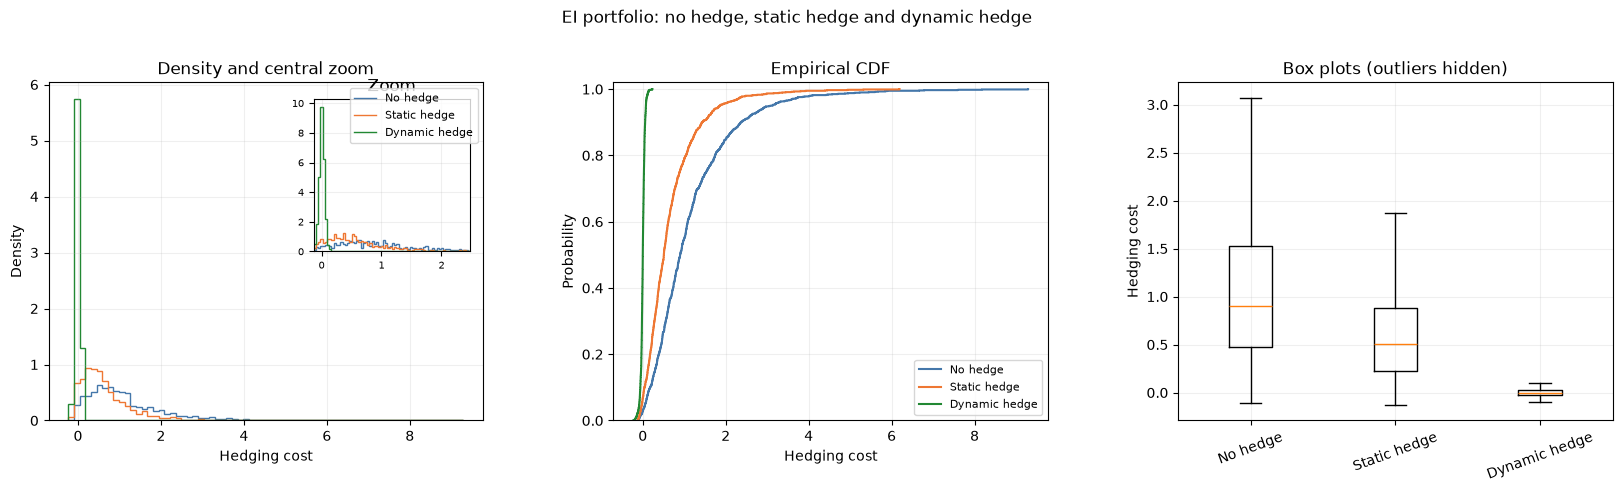

In [77]:
fig = result.plot()

plt.show()

### Reopen results without rerunning the simulation

`load_result()` opens an existing experiment.

The current analysis settings can then be reapplied to change normalization, quantiles or figures without generating new scenarios.

`save_analysis()` updates the saved analysis tables and figures. Changing market, population or hedging inputs requires a new simulation.

In [44]:
result = load_result(OUTPUT_DIRECTORY)

result.config["analysis"] = analysis.copy()

validate_config(result.config)

result.save_analysis(plots=SAVE_PLOTS)

print("Loaded experiment:", result.directory)

display(formatted_table(result.summary()))

Loaded experiment: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/notebooks/hedging_EI_CIR_T20_01


strategy,n,mean,variance,std,mean_se,mean_ci_low,mean_ci_high,min,max,probability_positive,q2.5,q50,q90,q95,q97.5,q99,es95,es99
no_hedge,10000,1.8096e-03,2.3306e-06,1.5266e-03,1.5266e-05,1.7796e-03,1.8395e-03,-1.8026e-04,1.6793e-02,9.6820e-01,-3.3063e-05,1.4568e-03,3.7134e-03,4.7019e-03,5.7262e-03,7.1842e-03,6.2702e-03,8.9137e-03
static_hedge,10000,6.4087e-04,3.8948e-07,6.2408e-04,6.2408e-06,6.2864e-04,6.5311e-04,-1.5423e-04,6.7930e-03,9.1850e-01,-8.9925e-05,4.9421e-04,1.4194e-03,1.8261e-03,2.2464e-03,2.8454e-03,2.4702e-03,3.5562e-03
dynamic_hedge,10000,4.1185e-07,7.5637e-11,8.6969e-06,8.6969e-08,2.4137e-07,5.8233e-07,-3.1578e-05,4.3826e-05,5.0580e-01,-1.5781e-05,1.1636e-07,1.1494e-05,1.5090e-05,1.8517e-05,2.2538e-05,1.9766e-05,2.6682e-05


In [45]:
h = result.config["hedging"]
timing = result.metadata["run"]

print("Outer scenarios:", h["outer_scenarios"])
print("Outer intervals:", h["intervals"])

print("Initial valuation:", h["initial"])
print("Revaluation:", h["revaluation"])

print("Actual threads:", timing.get("threads_used"))
print("Initial elapsed seconds:", timing.get("initial_wall_seconds"))
print("Outer elapsed seconds:", timing.get("simulation_wall_seconds"))

Outer scenarios: 10000
Outer intervals: 1040
Initial valuation: {'paths': 160, 'intervals': 128, 'configuration': 'conditioned_antithetic', 'carbon_seed': 2026101804, 'financial_seed': 2026101805}
Revaluation: {'paths': 40, 'intervals': 128, 'configuration': 'conditioned_antithetic', 'carbon_seed': 2026101806, 'financial_seed': 2026101807}
Actual threads: 16
Initial elapsed seconds: 0.004765301
Outer elapsed seconds: 1103.342088187
